# Divergence of the DC rule when β = 1 (Example 3)

This notebook checks numerically, with the `RVSDDP` package, the counterexample of Example 3 in the accompanying paper: in the average-cost case $\beta = 1$, RV-SDDP with the DC shift rule
$$\Delta_{n+1} = \min_{y \in \mathcal{X}} R^\Delta_n(y), \qquad R^\Delta_n := \mathcal{T}(V^\Delta_n) - V^\Delta_n,$$
lets the iterates diverge, although every state can be steered to any other in one step.

The problem has $T = 1$, a single noise value, $\mathcal{X} = \mathcal{U}(x) = [0, 1]$, $f(x, u) = u$ and
$$c(x, u) = 2x + \tfrac{1}{5} + K\,|x + u - 1|, \qquad K = 3.$$
Its optimal gain is $\varrho = 6/5$, attained by the 2-cycle $x \mapsto 1 - x$. The paper shows that, from $x_0 = 1/4$ and $\psi_0 = 0$:

1. every shift is $\Delta_n = 1/5$;
2. every new cut coincides with $\mathcal{T}(V^\Delta_n)$ on $\mathcal{X}$, and $V^\Delta_n(x) = \alpha_n x + b_n$ on $\mathcal{X}$, with $\alpha_0 = b_0 = 0$, $\alpha_{n+1} = 2 - \alpha_n$ and $b_{n+1} = b_n + \alpha_n$, i.e. $\alpha_n \in \{0, 2\}$ and $b_n = 2\lfloor n/2 \rfloor$;
3. the forward states alternate between $1/4$ and $3/4$;
4. hence $V^\Delta_n \geq n - 1$ on $\mathcal{X}$: the level grows by $\varrho - 1/5 = 1$ per cut, the part of the gain the shifts fail to absorb.

Each claim is checked below. Here $n$ counts cuts, as in the paper.

In [46]:
import Pkg
Pkg.activate(".")

  Activating project at `~/Documents/RVSDDP`


In [47]:
using RVSDDP
using Random
using Plots
using Gurobi
const GRB_ENV = Gurobi.Env()
Gurobi.GRBsetintparam(GRB_ENV, "Threads", 1)  # un seul thread, comme dans les scripts run_*.jl
optimizer=() -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05
Set parameter Threads to value 1


#205 (generic function with 1 method)

## The model

The control is the next state, $u = x^+$, so it is the outgoing state variable `x.out`; the absolute value is linearized with an epigraph variable `t`. The discount factor is $\beta = 1$, and the lower bound $\psi_0 = 0$ is the `lower_bound` of the value function. The constant $K$ can be replaced by any $K > 2$ (Remark of Example 3).

In [48]:
K = 3.0
x0 = 0.25

function subproblem_builder(subproblem::Model, node::Int, discount_factor::Float64)
    # State variable: x.in is the current state x, x.out is the control u = x+.
    @variable(subproblem, 0 <= x <= 1, RVSDDP.State, initial_value = x0)
    # t = |x + u - 1|
    @variable(subproblem, t >= 0)
    @constraint(subproblem, t >= x.in + x.out - 1)
    @constraint(subproblem, t >= 1 - x.in - x.out)
    @stageobjective(subproblem, 2 * x.in + 1 / 5 + K * t)
    return subproblem
end

graph = RVSDDP.InfiniteLinearGraph(1);

## The DC shift rule

The package ships `no_shift` and `random_shift`; the DC rule is written here as a custom shift rule, with the interface documented in `src/interfaces.jl`. It applies its shift with `apply_shift!` and returns it with the index of the cut it takes effect at.

The minimum of the residual over $\mathcal{X}$ is computed on a grid that contains both ends of $\mathcal{X}$. In general a grid only approximates the difference-of-convex minimum; here the paper shows that $R^\Delta_n$ is affine on $\mathcal{X}$, so its minimum is attained at $x = 0$ or $x = 1$ and the grid is exact. The rule records where the minimum is attained, and how far the residual is from affine, so that this can be checked below.

In [49]:
grid = range(0.0, 1.0; length = 1001)
argmin_log = Float64[]           # where the residual attains its minimum, one entry per cut
nonaffinity_log = Float64[]      # max distance of the residual to its chord on X

function dc_shift(model, node, batch_items, trial_states, candidates)
    residual = [
        RVSDDP.compute_TV(node, Dict(:x => y)) -
        RVSDDP.compute_V(node.value_function, Dict(:x => y)) for y in grid
    ]
    chord = residual[1] .+ (residual[end] - residual[1]) .* grid
    push!(nonaffinity_log, maximum(abs.(residual .- chord)))
    push!(argmin_log, grid[argmin(residual)])
    shift = max(minimum(residual), 0.0)
    RVSDDP.apply_shift!(model, node, shift)
    return (shift, RVSDDP.next_cut_index(node))
end

dc_shift (generic function with 1 method)

## Run RV-SDDP with the DC rule

The paper allows arbitrary forward-pass lengths; we use $L(k) = k$ as in the toy problem, so that 15 iterations generate $1 + 2 + \dots + 15 = 120$ cuts. The forward states are recorded through `forward_pass_callback`.

In [50]:
model = RVSDDP.PolicyGraph(
    subproblem_builder,
    graph;
    sense = :Min,
    lower_bound = 0.0,
    optimizer = optimizer,
    discount_factor = 1.0,
)

forward_states = Vector{Float64}[]
Random.seed!(1)
RVSDDP.train(
    model;
    refine_scheme = RVSDDP.refine_all,
    sampling_scheme = RVSDDP.InSampleMonteCarlo(rollout_limit = i -> i),
    iteration_limit = 15,
    infinite = true,
    shift_function = dc_shift,
    forward_pass_callback = traj -> push!(forward_states, [s[:x] for s in traj[1].sampled_states]),
);

cuts = model[1].value_function.cut_V[2:end]   # cut_V[1] is the lower bound psi0 = 0
N = length(cuts)

120

## Claim 1: every shift is 1/5

`cuts[n].shift[1]` is the shift $\Delta_n$ selected at the step that created cut $n$. The residual is affine, and its minimum alternates between the two ends of $\mathcal{X}$, one phase behind the 2-cycle.

In [51]:
Delta = [cut.shift[1][1] for cut in cuts]
println("max |Delta_n - 1/5|          = ", maximum(abs.(Delta .- 1 / 5)))
println("max distance of R_n to affine = ", maximum(nonaffinity_log))
println("argmin of R_n, first 10 cuts  = ", argmin_log[1:10])
@assert all(isapprox.(Delta, 1 / 5; atol = 1e-9))
@assert maximum(nonaffinity_log) < 1e-9
@assert all(in((0.0, 1.0)), argmin_log)

max |Delta_n - 1/5|          = 2.831068712794149e-15
max distance of R_n to affine = 1.0880185641326534e-14
argmin of R_n, first 10 cuts  = [0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0]


## Claim 2: the cuts and the iterates in closed form

Since $\mathcal{T}(V^\Delta_n)$ is affine on $\mathcal{X}$, cut $n+1$ coincides with it there:
$$\mathrm{cut}_{n+1}(x) = \mathcal{T}(V^\Delta_n)(x) = (2 - \alpha_n)\,x + \tfrac{1}{5} + \alpha_n + b_n .$$
Each stored cut is compared with this formula: `intercept` is its value at $x = 0$ and `coefficients[:x]` its slope.

In [52]:
alpha(n) = iseven(n) ? 0.0 : 2.0
b(n) = 2 * div(n, 2)

slope_error = maximum(abs(cuts[n+1].coefficients[:x] - (2 - alpha(n))) for n in 0:N-1)
intercept_error = maximum(abs(cuts[n+1].intercept - (1 / 5 + alpha(n) + b(n))) for n in 0:N-1)
println("max slope error     = ", slope_error)
println("max intercept error = ", intercept_error)
@assert slope_error < 1e-9 && intercept_error < 1e-9

max slope error     = 0.0
max intercept error = 5.551115123125783e-17


The iterates themselves are rebuilt with Proposition 6, $V^\Delta_n = \max\big(\psi_0, \max_{j \le n} \{\mathrm{cut}_j - \Delta^n_j\}\big)$ with the effective shifts $\Delta^n_j = \min_{j \le \ell \le n} \Delta_\ell$, and compared with $\alpha_n x + b_n$ on the grid.

In [53]:
function V(n, x)
    value = 0.0                                    # psi0
    for j in 1:n
        effective_shift = minimum(Delta[j:n])
        value = max(value, cuts[j].intercept + cuts[j].coefficients[:x] * x - effective_shift)
    end
    return value
end

iterate_error = maximum(abs(V(n, x) - (alpha(n) * x + b(n))) for n in 0:N, x in grid)
println("max |V_n(x) - (alpha_n x + b_n)| = ", iterate_error)
@assert iterate_error < 1e-9
# The final iterate is also the value function held by the model.
@assert maximum(abs(RVSDDP.compute_V(model[1].value_function, Dict(:x => x)) - V(N, x)) for x in grid) < 1e-9

max |V_n(x) - (alpha_n x + b_n)| = 1.4210854715202004e-14


### One step of the recursion, seen on $\mathcal{X}$

For a chosen $n$, the two plots show $V^\Delta_n$, $\mathcal{T}(V^\Delta_n)$ and the residual $R^\Delta_n = \mathcal{T}(V^\Delta_n) - V^\Delta_n$ at steps $n$ and $n + 1$. The DC rule takes $\Delta_{n+1} = \min_{\mathcal{X}} R^\Delta_n$ (marked by a dot), and the next iterate is $V^\Delta_{n+1} = \mathcal{T}(V^\Delta_n) - \Delta_{n+1}$ (dashed). Since $\alpha_n$ alternates, the residual tilts one way and then the other, and its minimum jumps between the two ends of $\mathcal{X}$.

$\mathcal{T}(V^\Delta_n)(x) = \min_{u \in [0, 1]} \{c(x, u) + V^\Delta_n(u)\}$ (here $\beta = 1$) is computed by its definition, on a grid of $u$ that contains the kink $u = 1 - x$ of the cost, so it is exact here; it is checked against the package's `compute_TV` for the last iterate, the only one the model still holds.

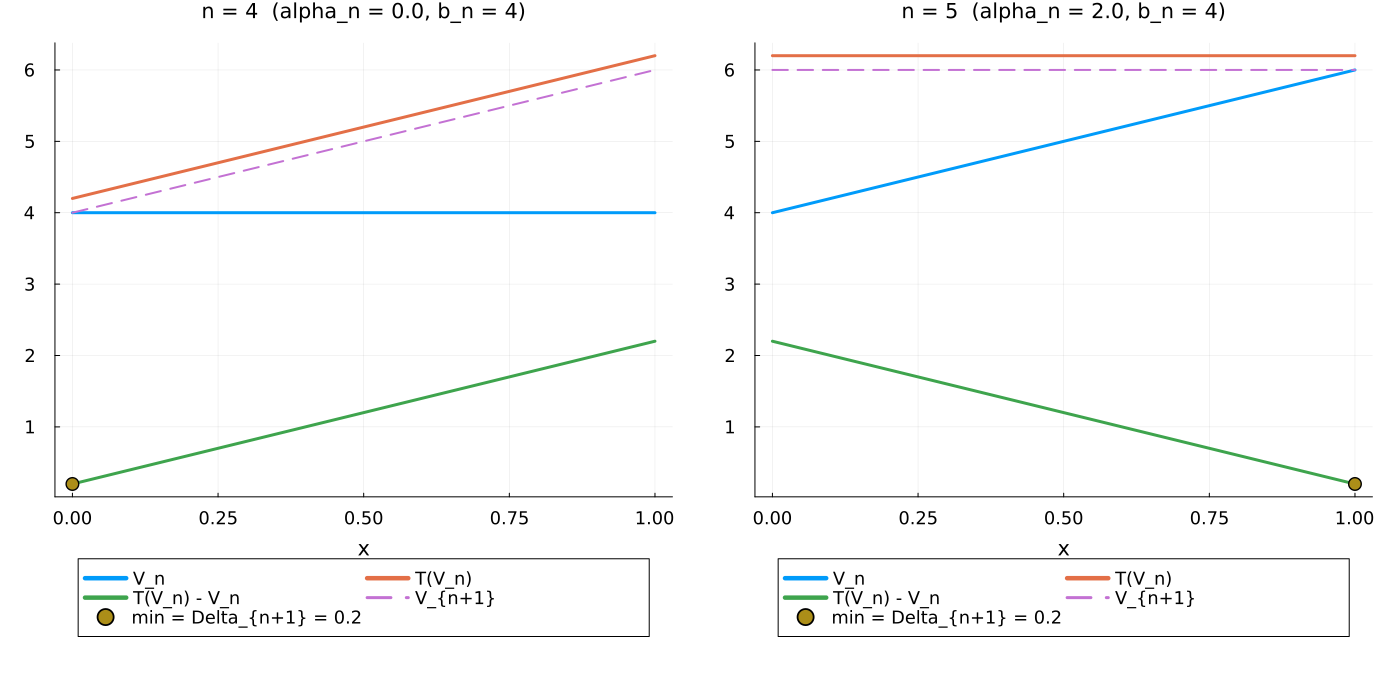

In [54]:
cost(x, u) = 2 * x + 1 / 5 + K * abs(x + u - 1)

# T(V_n) on the grid, from the values of V_n on the same grid (u = x+ is a state).
function TV(n)
    Vu = [V(n, u) for u in grid]
    return [minimum(cost(x, u) + Vu[k] for (k, u) in enumerate(grid)) for x in grid]
end

# Check against the package for the last iterate.
TV_N = TV(N)
@assert maximum(abs(TV_N[k] - RVSDDP.compute_TV(model[1], Dict(:x => x))) for (k, x) in enumerate(grid)) < 1e-9

function plot_step(n)
    Vn = [V(n, x) for x in grid]
    TVn = TV(n)
    Rn = TVn .- Vn
    k = argmin(Rn)
    p = plot(grid, Vn, label = "V_n", linewidth = 3, xlabel = "x",
        title = "n = $n  (alpha_n = $(alpha(n)), b_n = $(b(n)))",
        guidefontsize = 14, tickfontsize = 12, legendfontsize = 12, titlefontsize = 14,
        legend = :outerbottom, legend_columns = 2, margin = 5Plots.mm)
    plot!(p, grid, TVn, label = "T(V_n)", linewidth = 3)
    plot!(p, grid, Rn, label = "T(V_n) - V_n", linewidth = 3)
    plot!(p, grid, TVn .- Rn[k], label = "V_{n+1}", linewidth = 2, linestyle = :dash)
    scatter!(p, [grid[k]], [Rn[k]], label = "min = Delta_{n+1} = $(round(Rn[k], digits = 6))", markersize = 7)
    return p
end

n = 4
plot(plot_step(n), plot_step(n + 1), layout = (1, 2), size = (1400, 700), bottom_margin = 5Plots.mm)

## Claim 3: the forward states alternate between 1/4 and 3/4

Since $K > \alpha_n$, the unique Bellman minimizer is $u = 1 - x$, so the forward pass follows the optimal 2-cycle from $x_0 = 1/4$.

In [55]:
println("iteration 6: ", forward_states[6])
@assert all(all(s[i] == (isodd(i) ? 0.75 : 0.25) for i in eachindex(s)) for s in forward_states)

iteration 6: [0.75, 0.25, 0.75, 0.25, 0.75, 0.25]


## Claim 4: the iterates diverge

$V^\Delta_n \geq b_n = 2\lfloor n/2 \rfloor \geq n - 1$ on $\mathcal{X}$: the level grows by $1 = \varrho - 1/5$ per cut on average, the part of the optimal gain $\varrho = 6/5$ that the shifts $\Delta_n = 1/5$ fail to absorb.

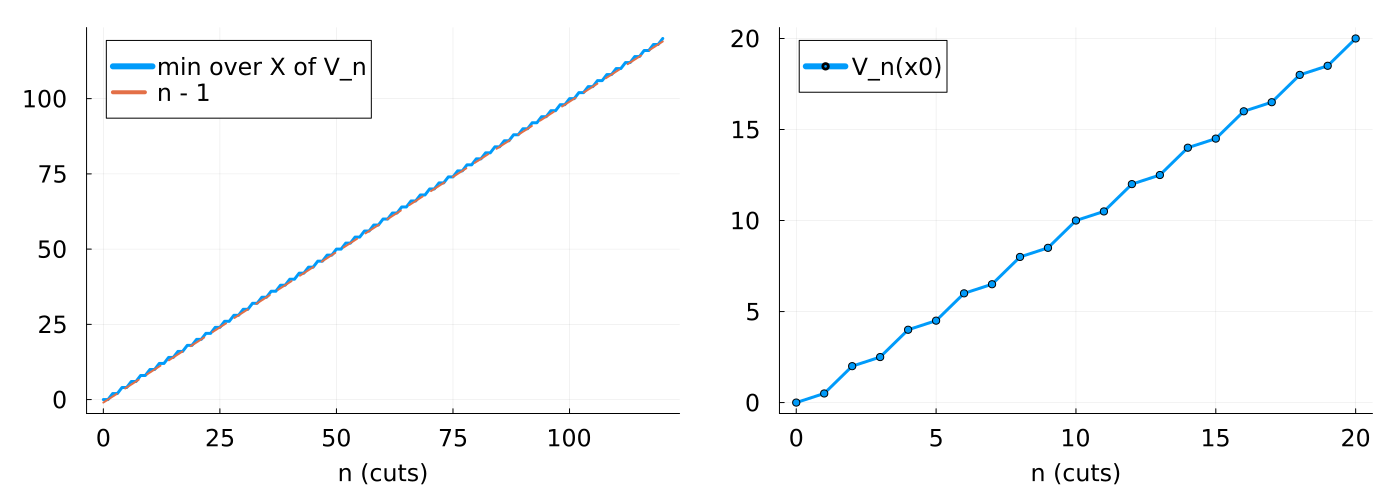

In [56]:
n = 0:N
fontsize = 16
p1 = plot(n, [minimum(V(k, x) for x in grid) for k in n], label = "min over X of V_n", linewidth = 3,
    xlabel = "n (cuts)", guidefontsize = fontsize, tickfontsize = fontsize, legendfontsize = fontsize,
    legend = :topleft, margin = 5Plots.mm)
plot!(p1, n, n .- 1, label = "n - 1", linewidth = 2, linestyle = :dash)
p2 = plot(n[1:21], [V(k, x0) for k in n[1:21]], label = "V_n(x0)", linewidth = 3, marker = :circle,
    xlabel = "n (cuts)", guidefontsize = fontsize, tickfontsize = fontsize, legendfontsize = fontsize,
    legend = :topleft, margin = 5Plots.mm)
plot(p1, p2, layout = (1, 2), size = (1400, 500), bottom_margin = 12Plots.mm)

## The same problem with β < 1

For $\beta < 1$ the DC rule satisfies the optimality criterion almost surely (Example 1 and Theorem 2). On this problem the slope recursion becomes $\alpha_{n+1} = 2 - \beta \alpha_n$: the oscillation of the slope is damped by a factor $\beta$ per cut, $\alpha_n \to 2/(1+\beta)$, and the residual $\mathcal{T}(V) - V$ becomes constant on $\mathcal{X}$, equal to the limiting shift $\delta$.

Set `beta` and `time_limit` below. The DC rule uses a coarser grid here, so that each cut costs 101 Bellman evaluations instead of 1001; the minimum is still exact, since the residual is affine on $\mathcal{X}$ and the grid contains both ends.

In [57]:
beta = 0.99
time_limit = 10

dc_grid = range(0.0, 1.0; length = 101)
function dc_shift_coarse(model, node, batch_items, trial_states, candidates)
    residual = [
        RVSDDP.compute_TV(node, Dict(:x => y)) -
        RVSDDP.compute_V(node.value_function, Dict(:x => y)) for y in dc_grid
    ]
    shift = max(minimum(residual), 0.0)
    RVSDDP.apply_shift!(model, node, shift)
    return (shift, RVSDDP.next_cut_index(node))
end

model_beta = RVSDDP.PolicyGraph(
    subproblem_builder,
    graph;
    sense = :Min,
    lower_bound = 0.0,
    optimizer = optimizer,
    discount_factor = beta,
)
Random.seed!(1)
RVSDDP.train(
    model_beta;
    refine_scheme = RVSDDP.refine_all,
    sampling_scheme = RVSDDP.InSampleMonteCarlo(rollout_limit = i -> i),
    time_limit = time_limit,
    infinite = true,
    shift_function = dc_shift_coarse,
);

cuts_beta = model_beta[1].value_function.cut_V[2:end]   # cut_V[1] is psi0 = 0
delta_beta = cuts_beta[end].shift[1][1]                  # last shift selected
println("cuts generated in $(time_limit) s : ", length(cuts_beta))
println("last shift                       : ", delta_beta)
println("slope of the last cut            : ", cuts_beta[end].coefficients[:x], "  (limit 2/(1+beta) = ", 2 / (1 + beta), ")")

cuts generated in 10 s : 1275
last shift                       : 0.20000000000001705
slope of the last cut            : 1.00502786121199  (limit 2/(1+beta) = 1.0050251256281406)


T(V) - V on X : min = 0.20000000000001705, max = 0.20000544381184682


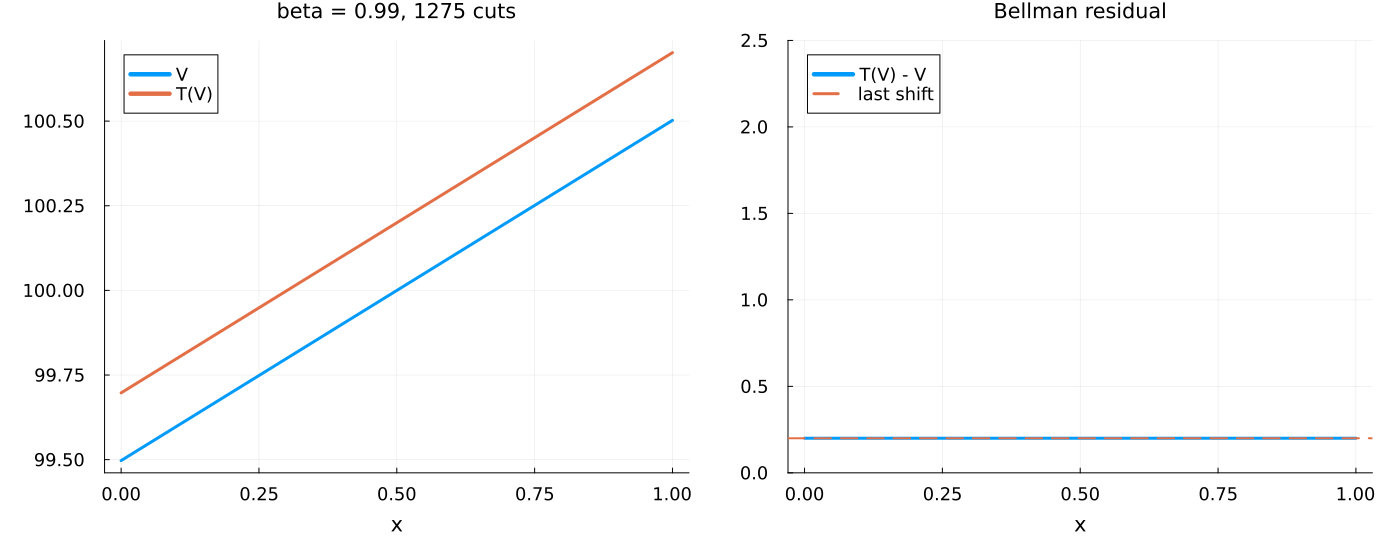

In [58]:
xs = range(0.0, 1.0; length = 201)
V_beta = [RVSDDP.compute_V(model_beta[1].value_function, Dict(:x => x)) for x in xs]
TV_beta = [RVSDDP.compute_TV(model_beta[1], Dict(:x => x)) for x in xs]
R_beta = TV_beta .- V_beta
println("T(V) - V on X : min = ", minimum(R_beta), ", max = ", maximum(R_beta))

fontsize = 14
p1 = plot(xs, V_beta, label = "V", linewidth = 3, xlabel = "x",
    title = "beta = $beta, $(length(cuts_beta)) cuts",
    guidefontsize = fontsize, tickfontsize = 12, legendfontsize = 12, titlefontsize = fontsize,
    legend = :topleft, margin = 5Plots.mm)
plot!(p1, xs, TV_beta, label = "T(V)", linewidth = 3)
p2 = plot(xs, R_beta, label = "T(V) - V", linewidth = 3, xlabel = "x",
    title = "Bellman residual",
    # Same scale as the beta = 1 plots above, where the residual spans [0.2, 2.2].
    ylims = (0, max(2.5, 1.1 * maximum(R_beta))),
    guidefontsize = fontsize, tickfontsize = 12, legendfontsize = 12, titlefontsize = fontsize,
    legend = :topleft, margin = 5Plots.mm)
hline!(p2, [delta_beta], label = "last shift", linewidth = 2, linestyle = :dash)
plot(p1, p2, layout = (1, 2), size = (1400, 550), bottom_margin = 10Plots.mm)

Here the optimal policy is still $u = 1 - x$ (the slope of $\beta V^*$ stays below $K$), which gives the optimal value in closed form, $V^*(x) = \big(2x + \tfrac{1}{5} + \beta(\tfrac{11}{5} - 2x)\big)/(1 - \beta^2)$. Proposition 4 with $T = 1$ predicts $V^*(x) = V(x) + \delta/(1-\beta)$ on the stable set, here $\{1/4, 3/4\}$; the gap shrinks as the run gets longer.

In [59]:
Vstar(x) = (2x + 1 / 5 + beta * (11 / 5 - 2x)) / (1 - beta^2)
for x in (0.25, 0.75)
    approx = RVSDDP.compute_V(model_beta[1].value_function, Dict(:x => x)) + delta_beta / (1 - beta)
    println("x = $x : V(x) + delta/(1-beta) = ", approx, "   V*(x) = ", Vstar(x), "   gap = ", abs(approx - Vstar(x)))
end

x = 0.25 : V(x) + delta/(1-beta) = 119.74847084410494   V*(x) = 119.74874371859279   gap = 0.0002728744878481848
x = 0.75 : V(x) + delta/(1-beta) = 120.25098477471094   V*(x) = 120.25125628140687   gap = 0.00027150669592401755


## The random-shift rule

The same runs with `RVSDDP.random_shift`, the rule used in the experiments of the paper (Example 2): the shift is the smallest residual over the trial state $x_n$ and one state $\zeta$ drawn uniformly in $\mathcal{X}$,
$$\Delta_{n+1} = \min\{R^\Delta_n(x_n), R^\Delta_n(\zeta_{n+1})\} \;\geq\; \min_{\mathcal{X}} R^\Delta_n .$$
It is therefore never smaller than the DC shift, and in general larger, since $R^\Delta_n$ here attains its minimum at an end of $\mathcal{X}$.

`run_rule` trains for `time_limit` seconds and `plot_run` shows $V$ and $\mathcal{T}(V)$, the residual $\mathcal{T}(V) - V$ (on the same scale as the plots above) and the sequence of shifts $\Delta_n$. Since the shifts are random, the limiting shift $\delta = \liminf_n \Delta_n$ is estimated by the smallest shift over the last quarter of the cuts.

In [60]:
function run_rule(beta, shift_function; time_limit = 10, seed = 1)
    model = RVSDDP.PolicyGraph(
        subproblem_builder,
        graph;
        sense = :Min,
        lower_bound = 0.0,
        optimizer = optimizer,
        discount_factor = beta,
    )
    Random.seed!(seed)
    RVSDDP.train(
        model;
        refine_scheme = RVSDDP.refine_all,
        sampling_scheme = RVSDDP.InSampleMonteCarlo(rollout_limit = i -> i),
        time_limit = time_limit,
        infinite = true,
        shift_function = shift_function,
    )
    return model
end

shift_sequence(model) = [cut.shift[1][1] for cut in model[1].value_function.cut_V[2:end]]
estimated_delta(model) = (D = shift_sequence(model); minimum(D[3 * length(D) ÷ 4:end]))
V_of(model, x) = RVSDDP.compute_V(model[1].value_function, Dict(:x => x))

function summarize(model, beta)
    D = shift_sequence(model)
    xs = range(0.0, 1.0; length = 201)
    R = [RVSDDP.compute_TV(model[1], Dict(:x => x)) - V_of(model, x) for x in xs]
    println("cuts                  : ", length(D))
    println("estimated delta       : ", estimated_delta(model))
    println("T(V) - V on X         : min = ", minimum(R), ", max = ", maximum(R))
    println("V(x0)                 : ", V_of(model, x0))
    println("slope V(1) - V(0)     : ", V_of(model, 1.0) - V_of(model, 0.0))
end

function plot_run(model, beta)
    xs = range(0.0, 1.0; length = 201)
    V = [V_of(model, x) for x in xs]
    TV = [RVSDDP.compute_TV(model[1], Dict(:x => x)) for x in xs]
    R = TV .- V
    D = shift_sequence(model)
    style = (guidefontsize = 14, tickfontsize = 12, legendfontsize = 12, titlefontsize = 14,
        legend = :topleft, margin = 5Plots.mm)
    p1 = plot(xs, V; label = "V", linewidth = 3, xlabel = "x",
        title = "beta = $beta, $(length(D)) cuts", style...)
    plot!(p1, xs, TV, label = "T(V)", linewidth = 3)
    p2 = plot(xs, R; label = "T(V) - V", linewidth = 3, xlabel = "x", title = "Bellman residual",
        ylims = (0, max(2.5, 1.1 * maximum(R))), style...)
    hline!(p2, [estimated_delta(model)], label = "estimated delta", linewidth = 2, linestyle = :dash)
    p3 = plot(D; label = "Delta_n", linewidth = 1, xlabel = "n (cuts)", title = "Shifts", style...)
    return plot(p1, p2, p3, layout = (1, 3), size = (1800, 550), bottom_margin = 10Plots.mm)
end

plot_run (generic function with 1 method)

### β = 1

Unlike the DC rule, the random shift keeps the iterates bounded on this example: the shifts settle at the optimal gain $\varrho = 6/5$, and the residual becomes constant, $\mathcal{T}(V) \approx V + \varrho$, i.e. $V$ solves the average-cost Bellman equation up to the run's accuracy. That equation has several solutions here, so $V$ need not be the affine $h(x) = x + 1/10$ of Example 3, only another relative value function with the same gain. This is an observation on this example only: the analysis of the paper covers $\beta < 1$, and the average-cost case is left to future work.

cuts                  : 6441
estimated delta       : 1.199687944550738
T(V) - V on X         : min = 1.1996879445507744, max = 1.2003120554492241
V(x0)                 : 7.861353982724841
slope V(1) - V(0)     : 0.9996879445507769
optimal gain rho      : 1.2


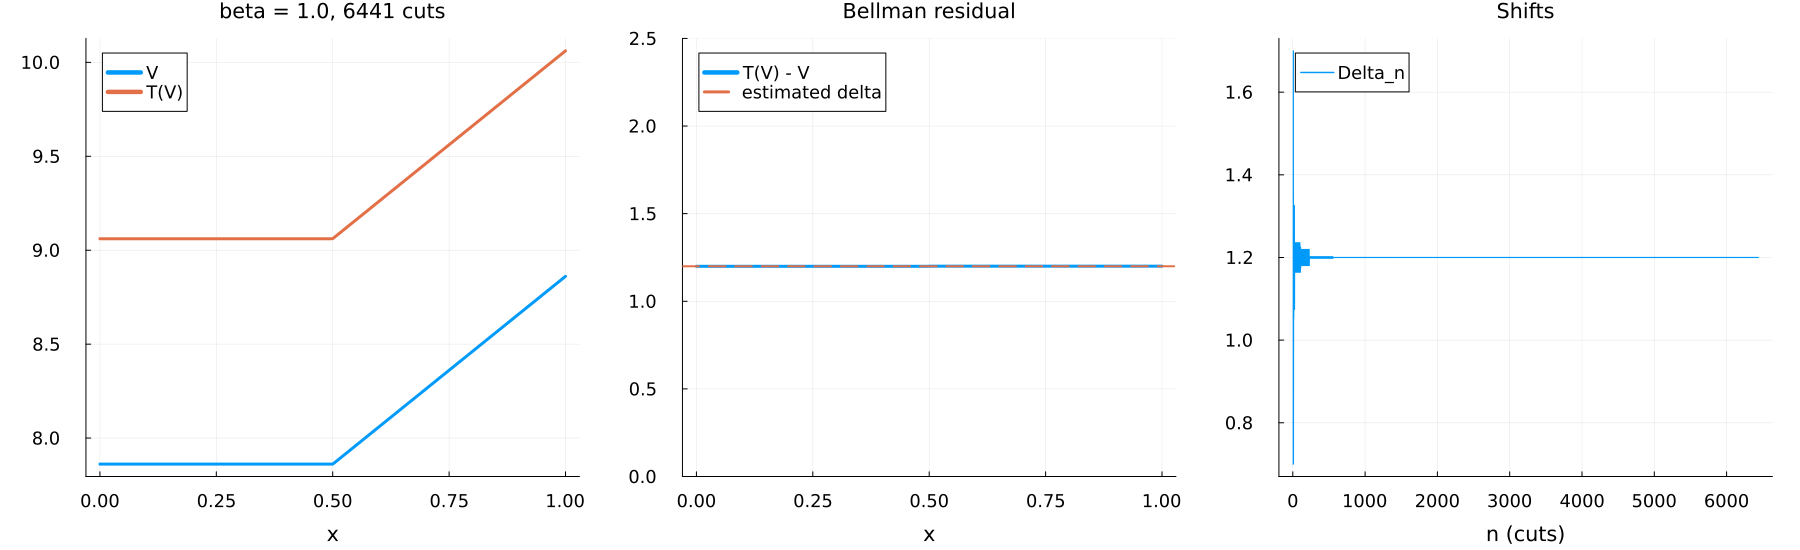

In [61]:
model_rand_1 = run_rule(1.0, RVSDDP.random_shift; time_limit = 10)
summarize(model_rand_1, 1.0)
println("optimal gain rho      : ", 6 / 5)
plot_run(model_rand_1, 1.0)

### β < 1

As for the DC rule, Proposition 4 with $T = 1$ predicts $V^*(x) = V(x) + \delta/(1-\beta)$ on the stable set $\{1/4, 3/4\}$, with $V^*$ in closed form as above. The gap shrinks as the run gets longer.

cuts                  : 7381
estimated delta       : 1.152495564836352
T(V) - V on X         : min = 1.152495564836351, max = 1.1527218411652305
V(x0)                 : 4.487324193552219
slope V(1) - V(0)     : 1.0049355466415975
x = 0.25 : V(x) + delta/(1-beta) = 119.73688067718732   V*(x) = 119.74874371859279   gap = 0.011863041405476338
x = 0.75 : V(x) + delta/(1-beta) = 120.23939311616977   V*(x) = 120.25125628140687   gap = 0.01186316523710218


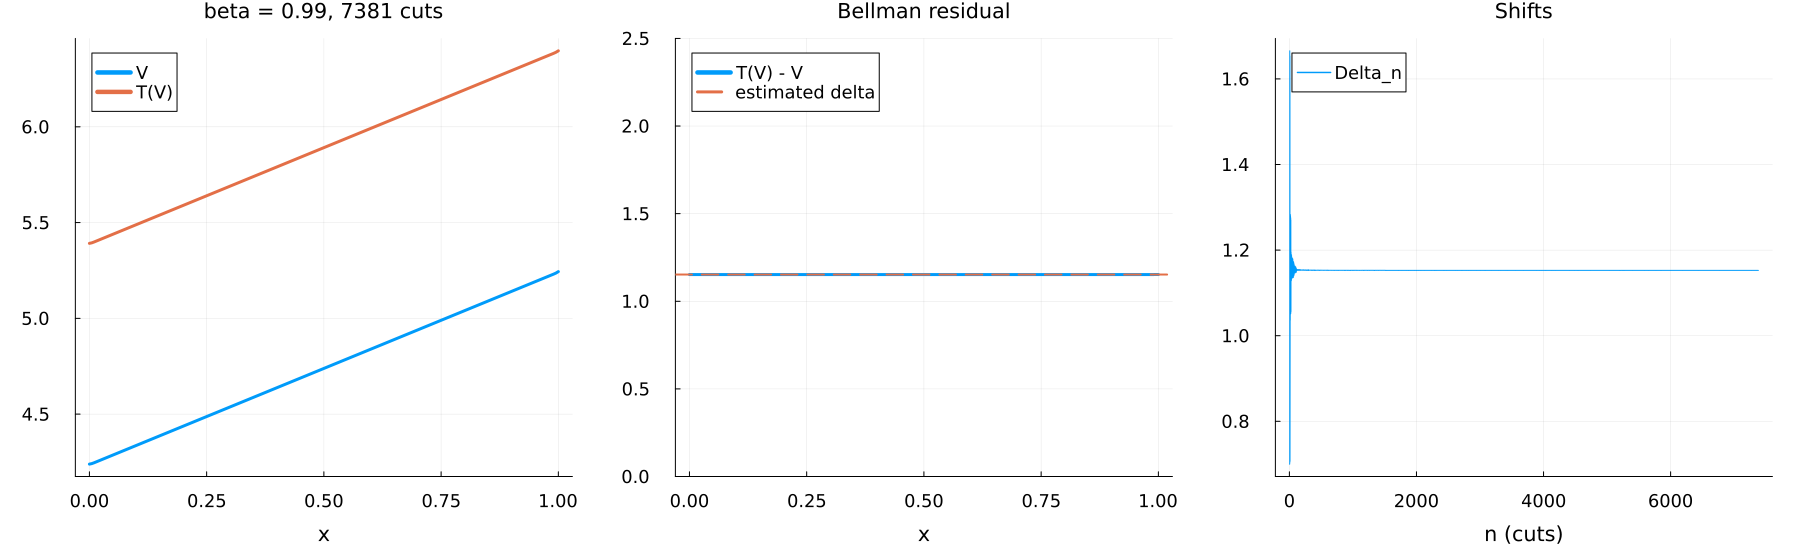

In [62]:
beta_rand = 0.99
model_rand_beta = run_rule(beta_rand, RVSDDP.random_shift; time_limit = 10)
summarize(model_rand_beta, beta_rand)
Vstar_rand(x) = (2x + 1 / 5 + beta_rand * (11 / 5 - 2x)) / (1 - beta_rand^2)
for x in (0.25, 0.75)
    approx = V_of(model_rand_beta, x) + estimated_delta(model_rand_beta) / (1 - beta_rand)
    println("x = $x : V(x) + delta/(1-beta) = ", approx, "   V*(x) = ", Vstar_rand(x), "   gap = ", abs(approx - Vstar_rand(x)))
end
plot_run(model_rand_beta, beta_rand)